# Nhiệm vụ 1.3: Phân tích Mức độ Thiếu Dữ liệu (Missingness Profile) & Bóc tách Ma trận 2 chiều (Source x Category)

**Thành viên thực hiện**: TV3 (Exploratory Data Analysis)

**Tập dữ liệu đầu vào**: `data/processed/products_processed.jsonl` (10.316 bản ghi, 30 thuộc tính chuẩn hóa)

**Mục tiêu**:
1. Khảo sát tỷ lệ missing (%) của toàn bộ 30 cột và phân loại mức độ nghiêm trọng.
2. Phân rã tỷ lệ missing theo 2 chiều: **Nguồn cào (Source)** x **Ngành hàng (Category)**.
3. Chứng minh hiện tượng **Thiếu mang tính Cấu trúc (Structural Missingness / MNAR)**: tại sao một số cột chỉ có ở Laptop, một số cột chỉ có ở Smartphone, và một số cột chỉ có ở một vài sàn cụ thể.
4. Cung cấp căn cứ thực nghiệm để TV5 xây dựng chiến lược Imputation phù hợp.

In [1]:
import os
import sys
from pathlib import Path

# Tự động định vị REPO_ROOT (chứa data/processed) và đưa working directory về root
curr = Path.cwd().resolve()
while curr != curr.parent:
    if (curr / "data" / "processed" / "products_processed.jsonl").exists():
        os.chdir(curr)
        break
    curr = curr.parent

if "src/eda/scripts" not in sys.path:
    sys.path.insert(0, "src/eda/scripts")

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from eda_stats import (
    load_processed_products,
    compute_overall_missingness,
    compute_missingness_by_category,
    compute_missingness_by_source,
    compute_missingness_matrix_source_category
)
from eda_viz import (
    set_plotting_theme,
    plot_overall_missingness_ranking,
    plot_missingness_heatmap_by_source_category,
    plot_hardware_missingness_comparison
)

set_plotting_theme()
print("Môi trường phân tích sẵn sàng!")

Môi trường phân tích sẵn sàng!


## 1. Tải dữ liệu và Xếp hạng Tỷ lệ Thiếu của Toàn bộ 30 Thuộc tính

In [2]:
df = load_processed_products("data/processed/products_processed.jsonl")
overall_miss_df = compute_overall_missingness(df)
display(overall_miss_df)

,Kiểu dữ liệu,Số mẫu Non-Null,Số mẫu Missing,Tỷ lệ Missing (%),Mức độ thiếu
Tên trường,,,,,
max_ram_gb,float64,353,9963,96.58,Cực cao (>80%) [Đặc thù ngành/sàn]
camera_mp,float64,814,9502,92.11,Cực cao (>80%) [Đặc thù ngành/sàn]
charger_watt,float64,880,9436,91.47,Cực cao (>80%) [Đặc thù ngành/sàn]
screen_size_inch,float64,1570,8746,84.78,Cực cao (>80%) [Đặc thù ngành/sàn]
network_type_norm,str,1720,8596,83.33,Cực cao (>80%) [Đặc thù ngành/sàn]
total_sold_normalized,float64,1904,8412,81.54,Cực cao (>80%) [Đặc thù ngành/sàn]
battery_wh,float64,1994,8322,80.67,Cực cao (>80%) [Đặc thù ngành/sàn]
battery_mah,float64,4159,6157,59.68,Cao (50-80%)
cpu_norm,str,4773,5543,53.73,Cao (50-80%)


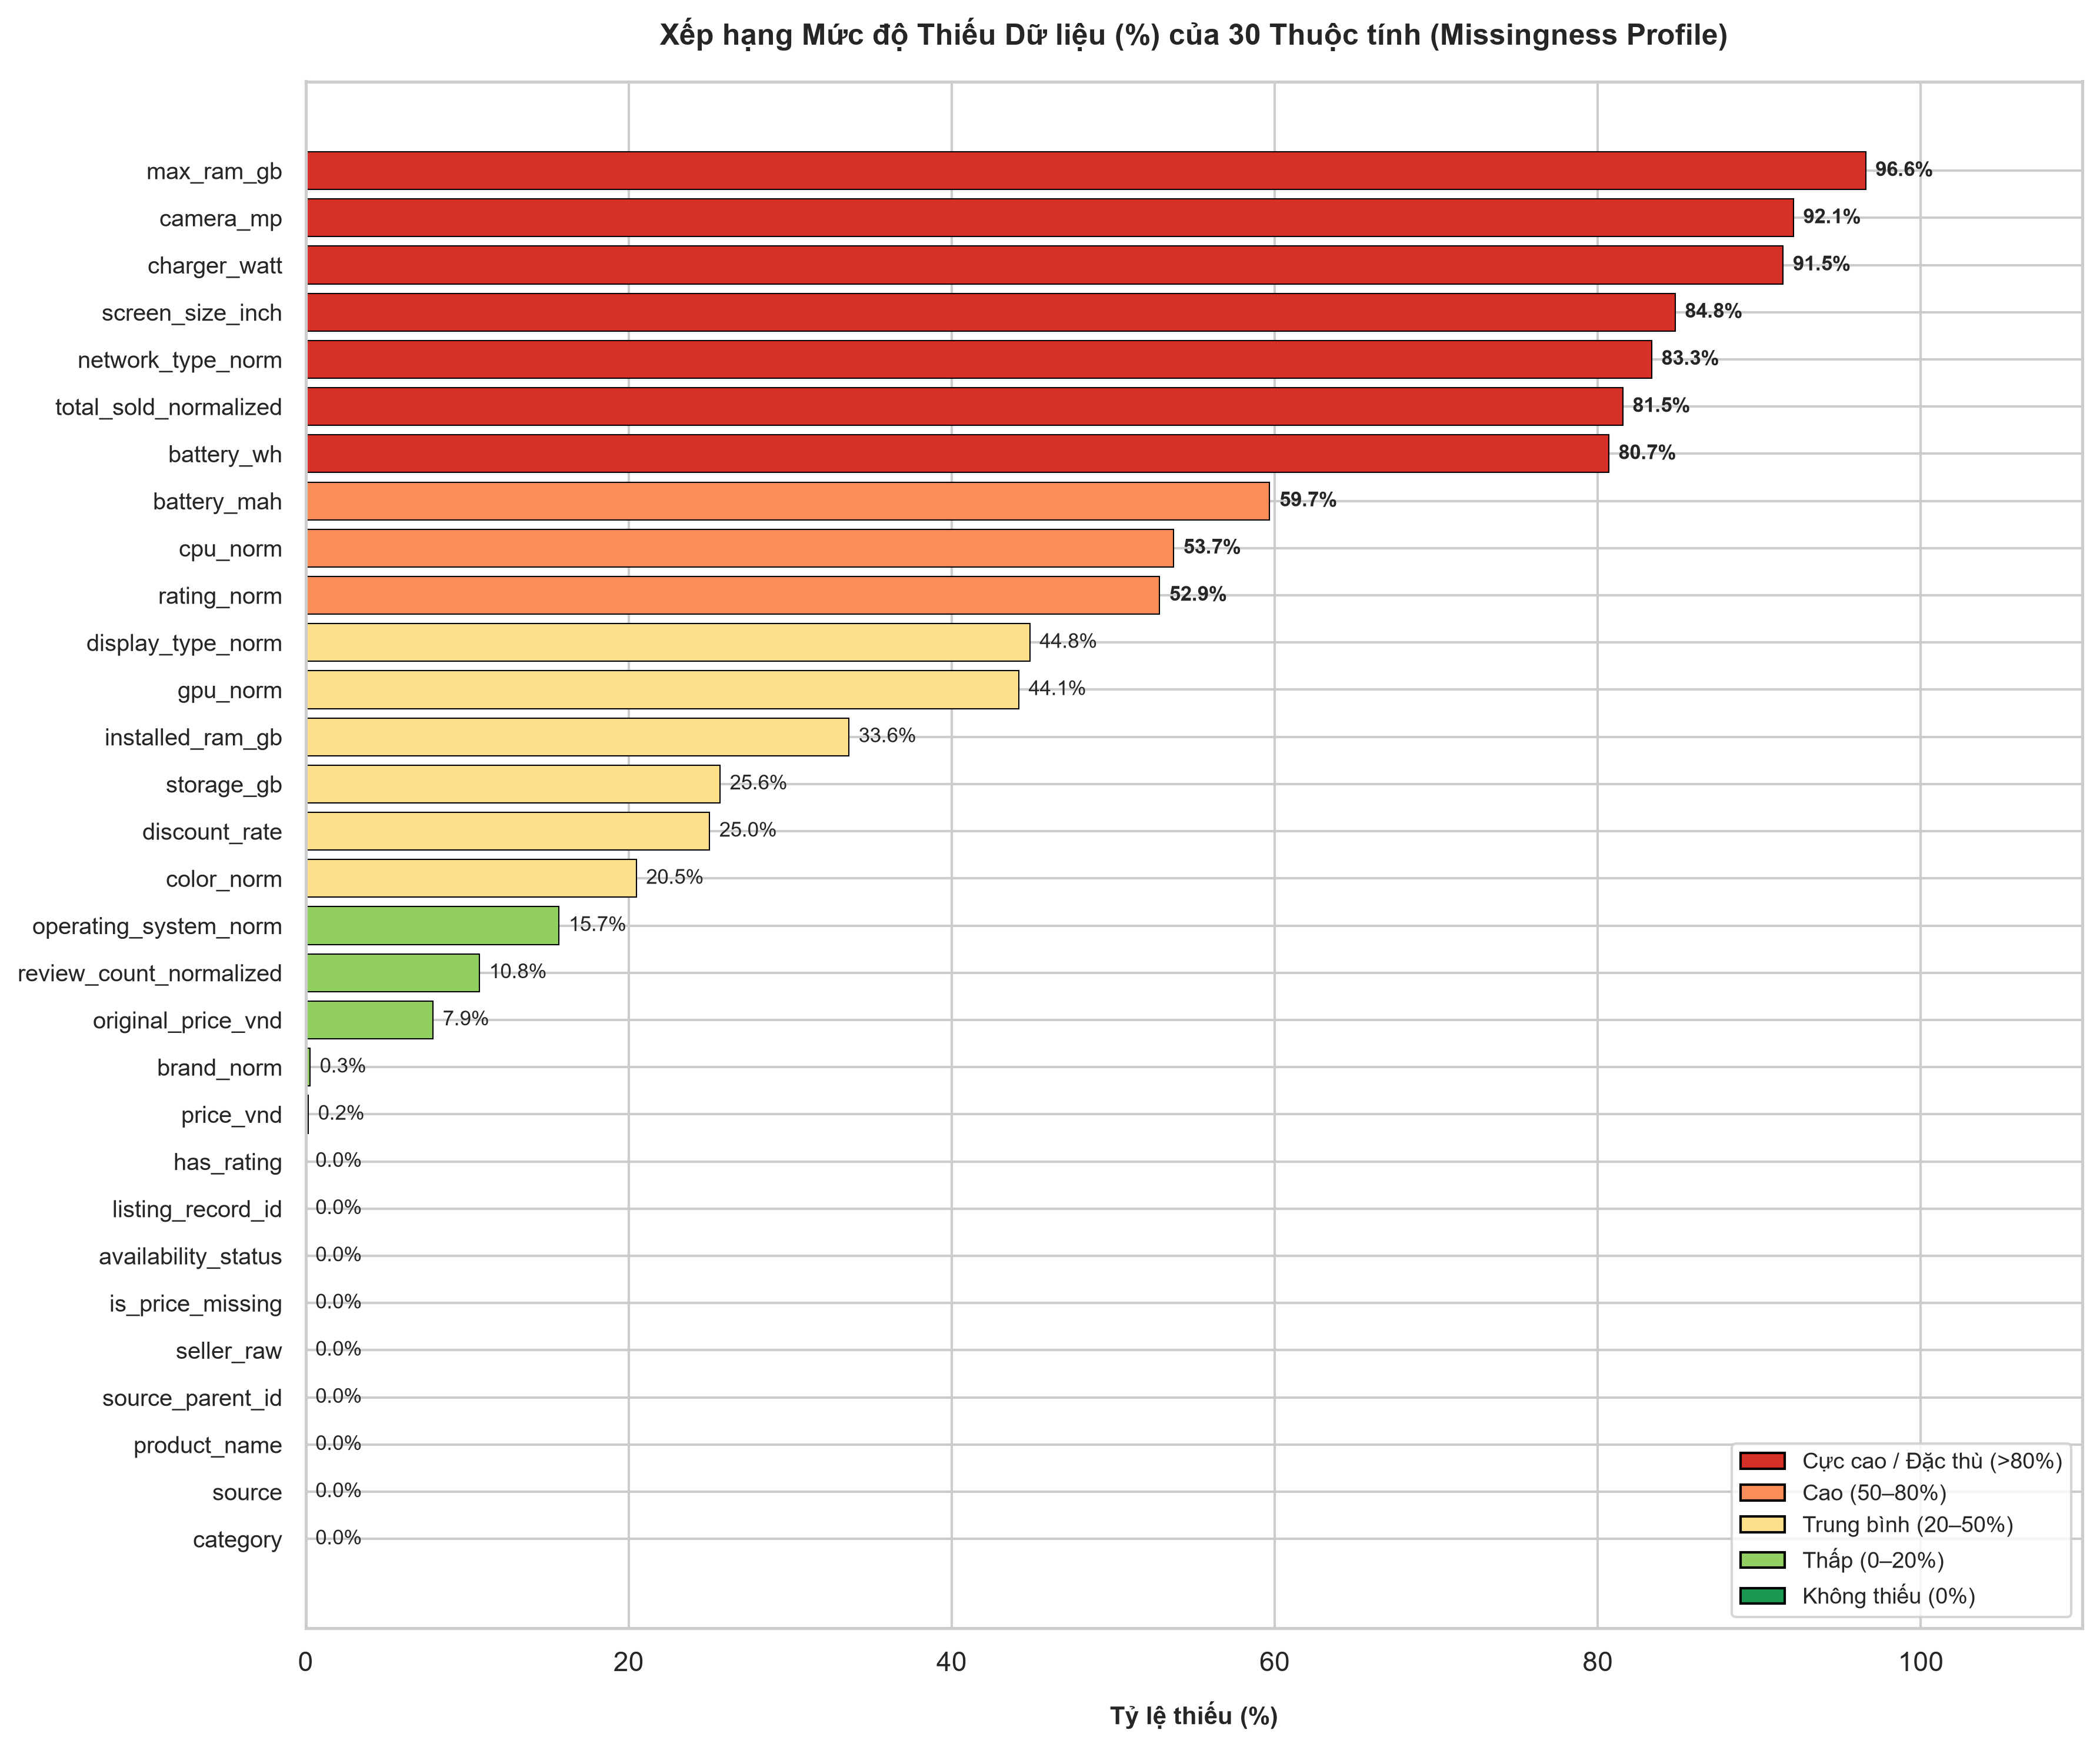

In [3]:
fig1_path = "src/eda/outputs/figures/fig_1_3_overall_missingness_ranking.png"
plot_overall_missingness_ranking(overall_miss_df, fig1_path)
from IPython.display import Image, display
display(Image(fig1_path))


## 2. So sánh Tỷ lệ Thiếu giữa Laptop và Smartphone — Khám phá Đặc thù Ngành hàng

In [4]:
cat_miss_df = compute_missingness_by_category(df)
display(cat_miss_df)

,Toàn thị trường (%),Laptop (%),Smartphone (%),Chênh lệch (Laptop - Phone),Bản chất khác biệt
max_ram_gb,96.58,92.76,100.00,-7.24,Thiếu tương đương giữa 2 ngành
camera_mp,92.11,97.11,87.63,9.48,Đặc thù phần cứng Smartphone (Pin mAh / Camera...
charger_watt,91.47,97.91,85.70,12.21,Thiếu tương đương giữa 2 ngành
screen_size_inch,84.78,79.83,89.21,-9.38,Thiếu tương đương giữa 2 ngành
network_type_norm,83.33,99.94,68.45,31.49,Đặc thù phần cứng Smartphone (Pin mAh / Camera...
total_sold_normalized,81.54,84.16,79.20,4.96,Thiếu tương đương giữa 2 ngành
battery_wh,80.67,59.15,99.94,-40.79,Đặc thù phần cứng Laptop (Pin Wh / GPU rời)
battery_mah,59.68,99.45,24.07,75.38,Đặc thù phần cứng Smartphone (Pin mAh / Camera...
cpu_norm,53.73,21.67,82.45,-60.78,Tỷ lệ khai báo CPU trên Laptop cao vượt trội
rating_norm,52.86,68.47,38.88,29.59,Người dùng Smartphone đánh giá nhiều hơn Laptop


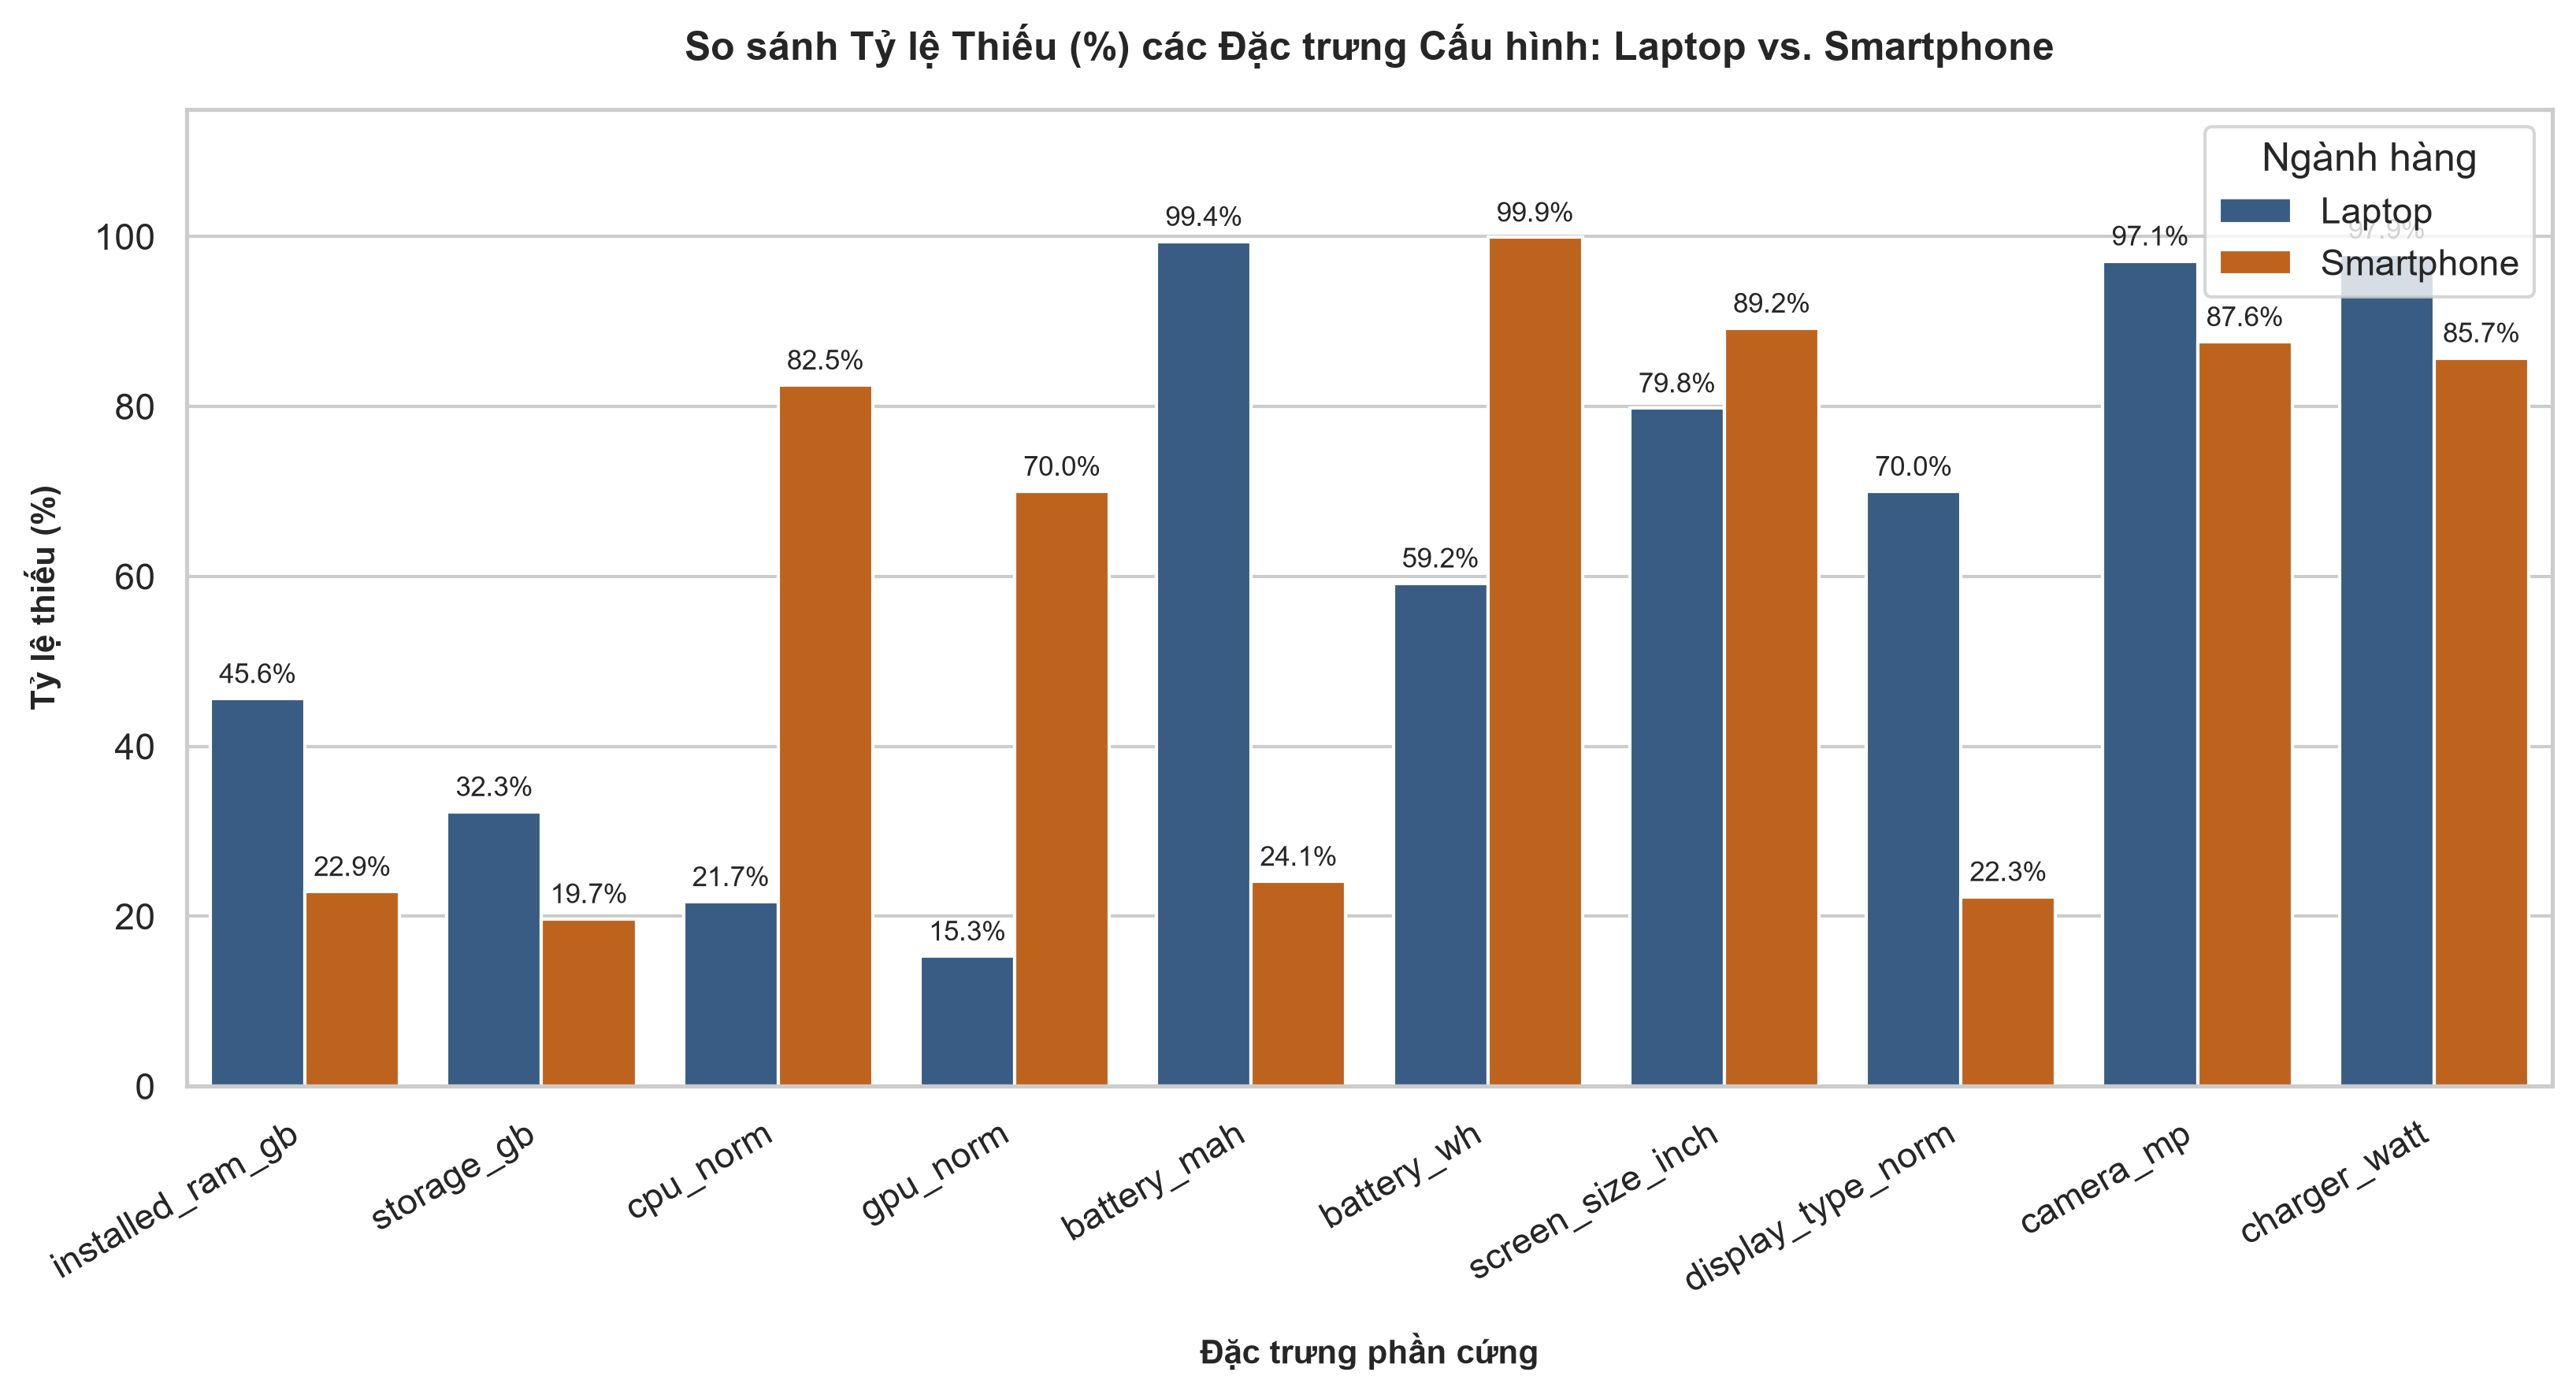

In [5]:
fig3_path = "src/eda/outputs/figures/fig_1_3_hardware_missingness_laptop_vs_phone.png"
plot_hardware_missingness_comparison(df, fig3_path)
from IPython.display import Image, display
display(Image(fig3_path))


## 3. Ma trận Biểu đồ Nhiệt (Heatmap) Phân rã 2 chiều: Source x Category

In [6]:
source_miss_df = compute_missingness_by_source(df)
display(source_miss_df)

matrix_2d_df = compute_missingness_matrix_source_category(df)
display(matrix_2d_df)

,price_vnd,original_price_vnd,discount_rate,rating_norm,total_sold_normalized,installed_ram_gb,storage_gb,cpu_norm,gpu_norm,battery_mah,battery_wh,screen_size_inch,charger_watt
cellphones,0.00,0.00,22.48,62.52,100.00,34.99,16.04,46.83,40.63,56.35,81.18,98.84,100.00
fptshop,0.00,0.00,0.12,12.68,6.46,30.49,88.54,48.17,76.71,96.59,100.00,0.98,100.00
hoanghamobile,0.70,9.47,9.47,100.00,100.00,63.86,54.39,50.18,65.61,71.23,89.82,54.74,69.47
tgdd,0.84,62.99,62.99,4.85,5.01,18.71,31.41,98.33,43.53,56.39,60.32,59.40,43.02
viettelstore,2.40,19.16,19.76,59.88,100.00,40.12,77.84,91.62,17.96,38.92,92.22,68.86,33.53
Toàn thị trường,0.16,7.88,25.00,52.86,81.54,33.63,25.65,53.73,44.15,59.68,80.67,84.78,91.47


price_vnd  rating_norm  total_sold_normalized  \
source        category                                                    
cellphones    laptop            0.0         79.2                  100.0   
              smartphone        0.0         46.0                  100.0   
fptshop       laptop            0.0         21.1                    6.7   
              smartphone        0.0          6.2                    6.2   
hoanghamobile laptop            0.0        100.0                  100.0   
              smartphone        1.0        100.0                  100.0   
tgdd          laptop            0.4         10.2                   10.2   
              smartphone        1.1          1.1                    1.4   
viettelstore  laptop            0.0         95.7                  100.0   
              smartphone        2.8         54.2                  100.0   

                          installed_ram_gb  storage_gb  cpu_norm  gpu_norm  \
source        category                                                       
cellphones    laptop                  48.1        21.8      12.8       0.8   
              smartphone              22.0        10.3      80.7      80.2   
fptshop       laptop                  46.6       100.0       7.0      48.6   
              smartphone              18.1        79.7      79.7      98.3   
hoanghamobile laptop                  66.7        44.1      22.6      55.9   
              smartphone              62.5        59.4      63.5      70.3   
tgdd          laptop                  18.8        61.0      99.6      98.6   
              smartphone              18.7        10.9      97.5       5.4   
viettelstore  laptop                  91.3       100.0     100.0      21.7   
              smartphone              31.9        74.3      90.3      17.4   

                          battery_mah  battery_wh  screen_size_inch  
source        category                                               
cellphones    laptop             99.3        62.3              98.1  
              smartphone         13.6        99.9              99.6  
fptshop       laptop            100.0       100.0               0.0  
              smartphone         94.0       100.0               1.7  
hoanghamobile laptop             98.9        68.8              34.4  
              smartphone         57.8       100.0              64.6  
tgdd          laptop            100.0         3.1               1.2  
              smartphone         26.2       100.0              99.7  
viettelstore  laptop            100.0        43.5              65.2  
              smartphone         29.2       100.0              69.4

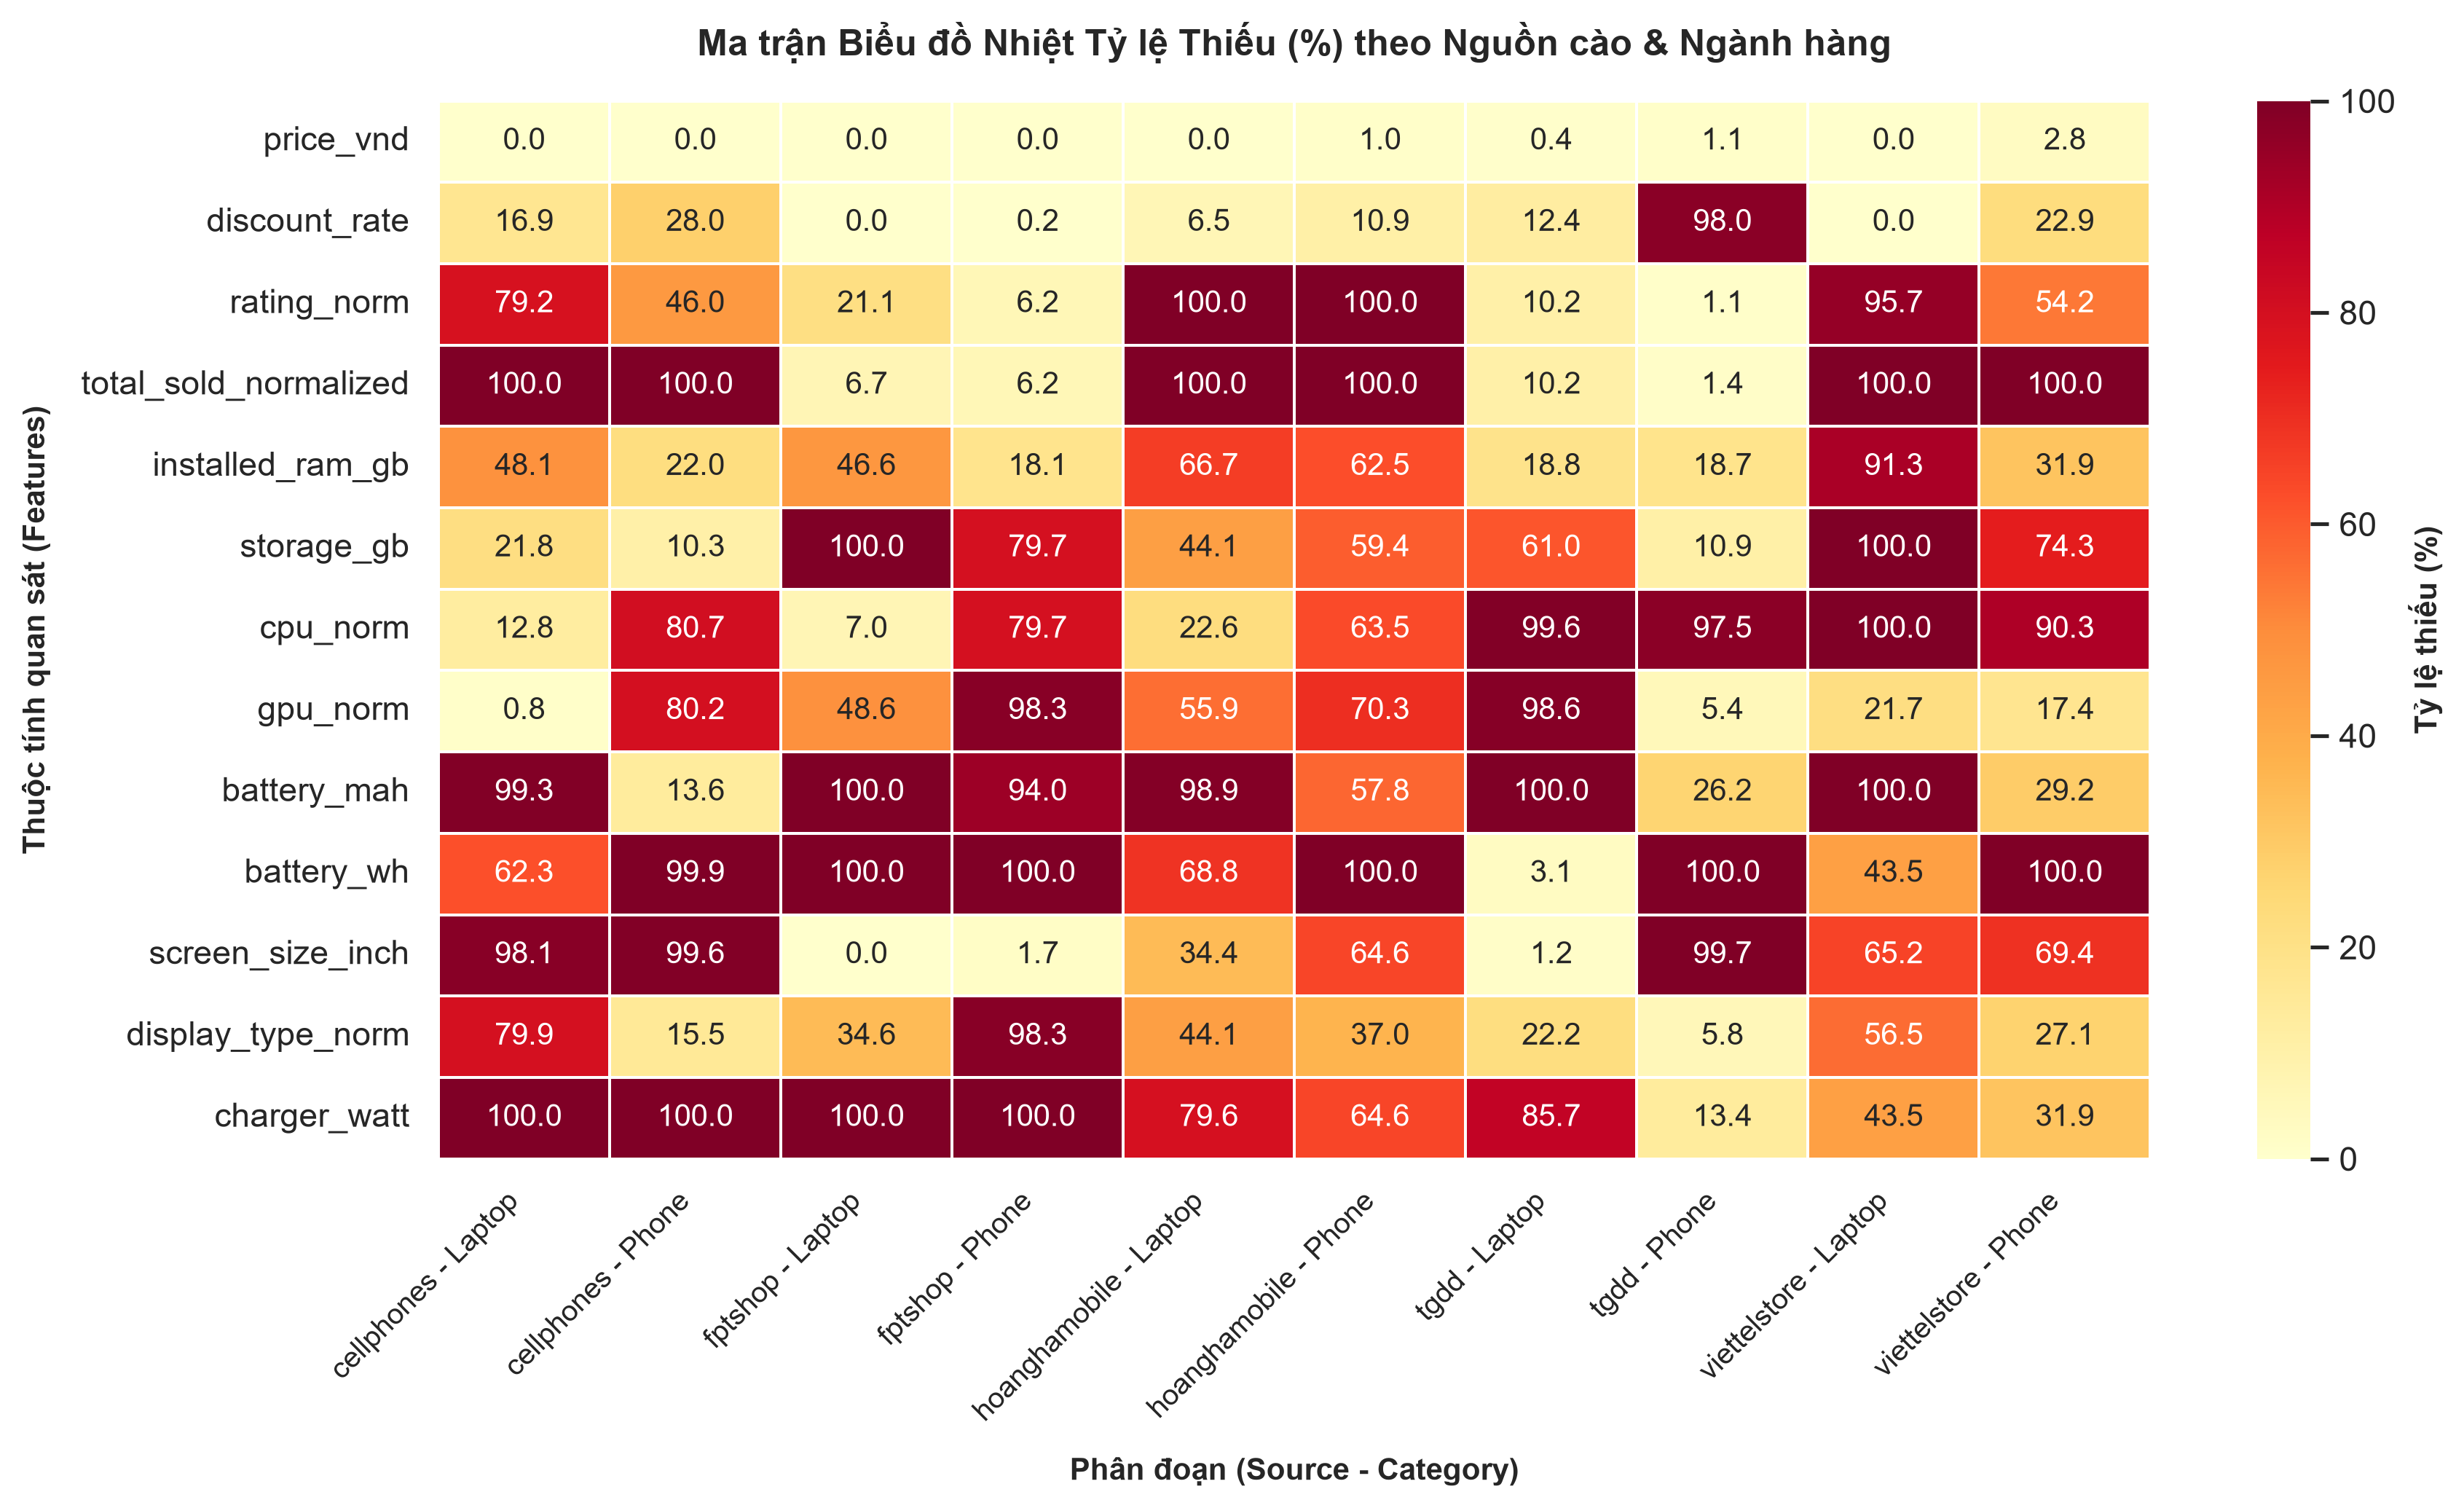

In [7]:
fig2_path = "src/eda/outputs/figures/fig_1_3_missingness_heatmap_by_source_category.png"
plot_missingness_heatmap_by_source_category(df, fig2_path)
from IPython.display import Image, display
display(Image(fig2_path))


## 4. Kết luận cốt lõi & Khuyến nghị Tiền xử lý cho TV5

1. **Nhóm đặc trưng hoàn chỉnh (Missing 0.0% – 0.3%)**:
   * `listing_record_id`, `source_parent_id`, `product_name`, `source`, `category`, `seller_raw`, `availability_status`, `is_price_missing`, `has_rating` (100% đầy đủ).
   * `price_vnd` (chỉ thiếu 0,16% — 16 bản ghi lỗi).
   * `brand_norm` (chỉ thiếu 0,27% — 28 bản ghi).
   * *Khuyến nghị*: Đây là bộ khung chuẩn hóa cực kỳ vững chắc.

2. **Hiện tượng Thiếu mang tính Cấu trúc theo Ngành hàng (Category-Specific Structural Missingness)**:
   * `battery_wh` (Laptop thiếu 59,2%, Smartphone thiếu 99,9%).
   * `battery_mah` (Laptop thiếu 99,4%, Smartphone thiếu 24,1%).
   * `gpu_norm` (Laptop thiếu 15,3%, Smartphone thiếu 70,0%).
   * `cpu_norm` (Laptop thiếu 21,7%, Smartphone thiếu 82,5%).
   * `camera_mp` (Laptop thiếu 97,1%, Smartphone thiếu 87,6%).
   * *Khuyến nghị cho TV5*: **Bắt buộc phải tách thành 2 mô hình huấn luyện độc lập**: 1 mô hình cho Laptop và 1 mô hình cho Smartphone. Không được gộp chung rồi cố điền Pin Wh cho Smartphone hay điền Camera MP cho Laptop.

3. **Hiện tượng Thiếu mang tính Cấu trúc theo Sàn cào (Source-Specific Missingness)**:
   * `total_sold_normalized`: Chỉ tồn tại ở **FPT Shop** (thiếu 6,5%) và **TGDĐ** (thiếu 5,0%). Thiếu 100% tại CellphoneS, Hoàng Hà, Viettel Store do các website này không công khai số lượng đã bán.
   * `charger_watt`: Thiếu 100% tại CellphoneS và FPT Shop, nhưng có ở TGDĐ và Viettel Store.
   * `rating_norm`: Thiếu 100% tại Hoàng Hà Mobile do sàn không có hệ thống đánh giá sao công khai, nhưng ở TGDĐ chỉ thiếu 4,8%.
   * *Khuyến nghị cho TV5*: Tuyệt đối không dùng `total_sold_normalized` làm đặc trưng dự đoán giá chung nếu mô hình áp dụng đa sàn, vì sẽ gây ra hiện tượng rò rỉ thiên lệch sàn (Source Bias Leakage).